# 01 · Exploratory data analysis — SNAP ego-Twitter

**Project:** Community Detection Among Social Media Users Based on Common Interests Using the Label Propagation Algorithm

This notebook looks at the cleaned data in `data/processed/` before any community detection.
It answers three questions:

1. **How big and how connected is the follow graph?**
2. **How much interest information (hashtags, mentions) do users have?**
3. **What do the ground-truth circles look like**, and how fair is it to compare communities with them?

All numbers come from `pipeline/eda.py` (tested in `tests/test_eda.py`), so the notebook stays short.
Run `python -m pipeline.download` and `python -m pipeline.preprocess` first.

In [3]:
import json
import os
from pathlib import Path

# Run from the project root so data/ and outputs/ paths work
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import pandas as pd
from IPython.display import Image, display

from pipeline import eda

FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
t = eda.load("data/processed")
stats = {**eda.dataset_stats(t), **eda.token_filter_stats(Path("data/raw/twitter"))}

def show(plot, name):
    plot(t, FIG / name)
    display(Image(filename=str(FIG / name)))

## 1. Dataset size

In [2]:
pd.Series({
    "users": stats["users"],
    "follow edges (unique)": stats["follow_edges"],
    "ego networks": stats["egos"],
    "ego networks without circles": stats["egos_without_circles"],
    "circles": stats["n_circles"],
    "distinct interest tokens": stats["n_tokens"],
    "  of which hashtags": stats["n_hashtags"],
    "  of which mentions": stats["n_mentions"],
}).map("{:,}".format).to_frame("count")

,count
users,"81,306"
follow edges (unique),"1,762,504"
ego networks,973
ego networks without circles,35
circles,"4,065"
distinct interest tokens,"155,454"
of which hashtags,"24,032"
of which mentions,"131,422"


## 2. Cleaning the interest tokens

Each ego network has its own `.featnames` file mapping feature indices to tokens such as `#python` or `@nasa`.
Preprocessing (`pipeline/preprocess.py → normalize_token`) cleans them in three steps:

| Step | Why |
|---|---|
| lowercase | `#Python` and `#python` are the same interest |
| cut to word characters | `@mashable:` comes from tweet text like *"RT @mashable: …"* and is the same account as `@mashable` |
| drop junk | digits-only (`#1`) or punctuation-only (`#...`) tokens carry no interest |

In [3]:
steps = pd.Series({
    "raw distinct feature names": stats["raw_tokens"],
    "after lowercasing": stats["after_lowercase"],
    "after cutting punctuation + dropping junk": stats["after_cleaning"],
})
steps.to_frame("distinct tokens").assign(
    removed=lambda d: (-d["distinct tokens"].diff()).fillna(0).astype(int)
).style.format("{:,}")

,distinct tokens,removed
raw distinct feature names,"216,817",0
after lowercasing,"198,458","18,359"
after cutting punctuation + dropping junk,"155,454","43,004"


Cleaning merges **61,363** duplicate spellings (216,817 → 155,454).
The punctuation step alone matters most: before it, about 30% of tokens ended in a stray character (mostly `:` from retweets),
so the same interest was split into unrelated tokens.

SNAP had already removed tokens used by only one user (every token is shared by at least 2 users),
so the `--min-token-users 2` filter in preprocessing changes nothing on this dataset.

## 3. Follow graph

Twitter follows are directed: *a follows b* does not mean *b follows a*.

In [4]:
pd.Series({
    "reciprocity (share of follows that are mutual)": f"{stats['reciprocity']:.1%}",
    "users with no follow edges": f"{stats['users_without_follow_edges']:,}",
    "median followers (in-degree)": stats["in_degree_median"],
    "max followers": f"{stats['in_degree_max']:,}",
    "median following (out-degree)": stats["out_degree_median"],
    "max following": f"{stats['out_degree_max']:,}",
}).to_frame("value")

,value
reciprocity (share of follows that are mutual),48.3%
users with no follow edges,"5,037"
median followers (in-degree),9.0
max followers,"3,383"
median following (out-degree),10.0
max following,"1,205"


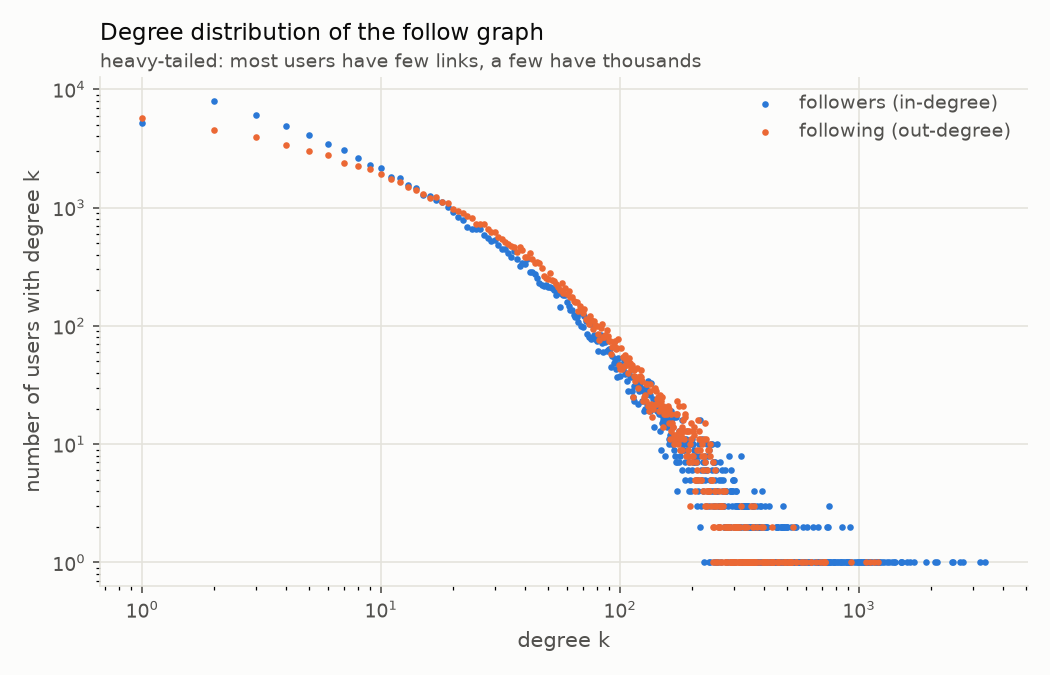

In [5]:
show(eda.plot_degree_distribution, "eda_degree_distribution.png")

**Reading:** both degree distributions are heavy-tailed (a straight-ish line on log–log axes): most users have a
handful of links while a few accounts have thousands. About **48%** of follows are mutual, so
`--direction mutual` keeps roughly half of the edges — the stronger, two-way ties.

## 4. Ego networks: size and density

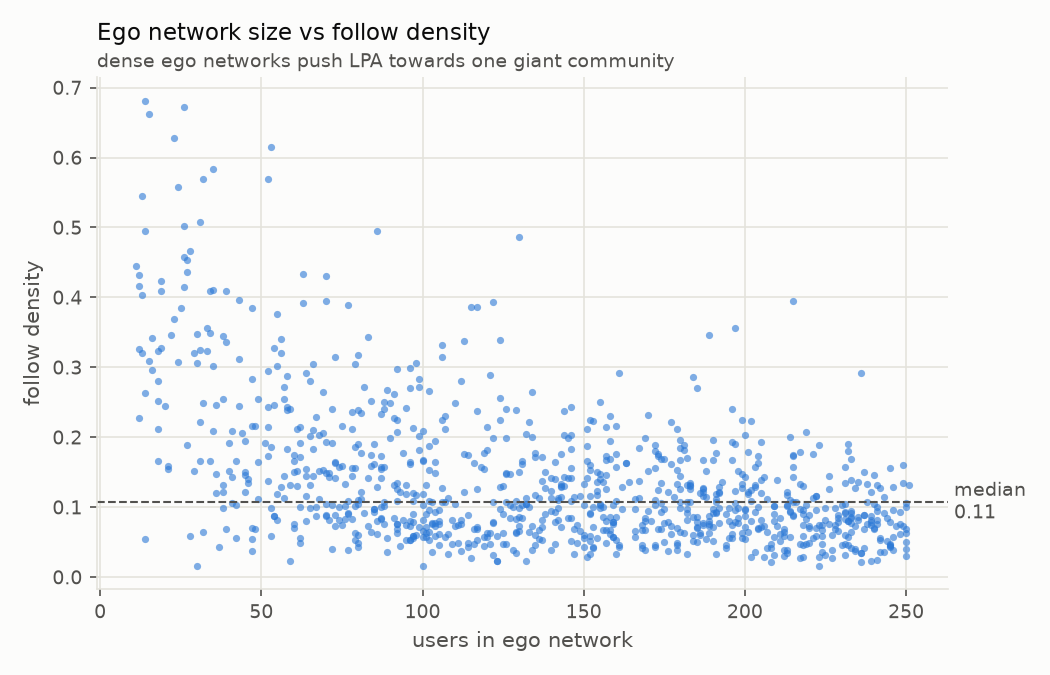

In [6]:
show(eda.plot_ego_density, "eda_ego_density.png")

**Reading:** ego networks have at most 251 users (median 141), and a median of **11%** of all possible
follow pairs exist. For a social graph that is very dense. In a graph this dense, LPA labels spread everywhere and tend to merge into
one giant community — exactly what step 5 found with `--direction any` (≈80% of users in one community).
Smaller egos are even denser (up to 68%).

## 5. Interests: hashtags and mentions

In [7]:
pd.Series({
    "users with ≥1 hashtag": f"{stats['share_with_hashtag']:.1%}",
    "users with ≥1 mention": f"{stats['share_with_mention']:.1%}",
    "users with no tokens": f"{stats['share_with_no_tokens']:.1%}",
    "median tokens per user (all users)": stats["tokens_per_user_median"],
    "median users per token": stats["users_per_token_median"],
}).to_frame("value")

,value
users with ≥1 hashtag,64.2%
users with ≥1 mention,83.2%
users with no tokens,13.4%
median tokens per user (all users),11.0
median users per token,3.0


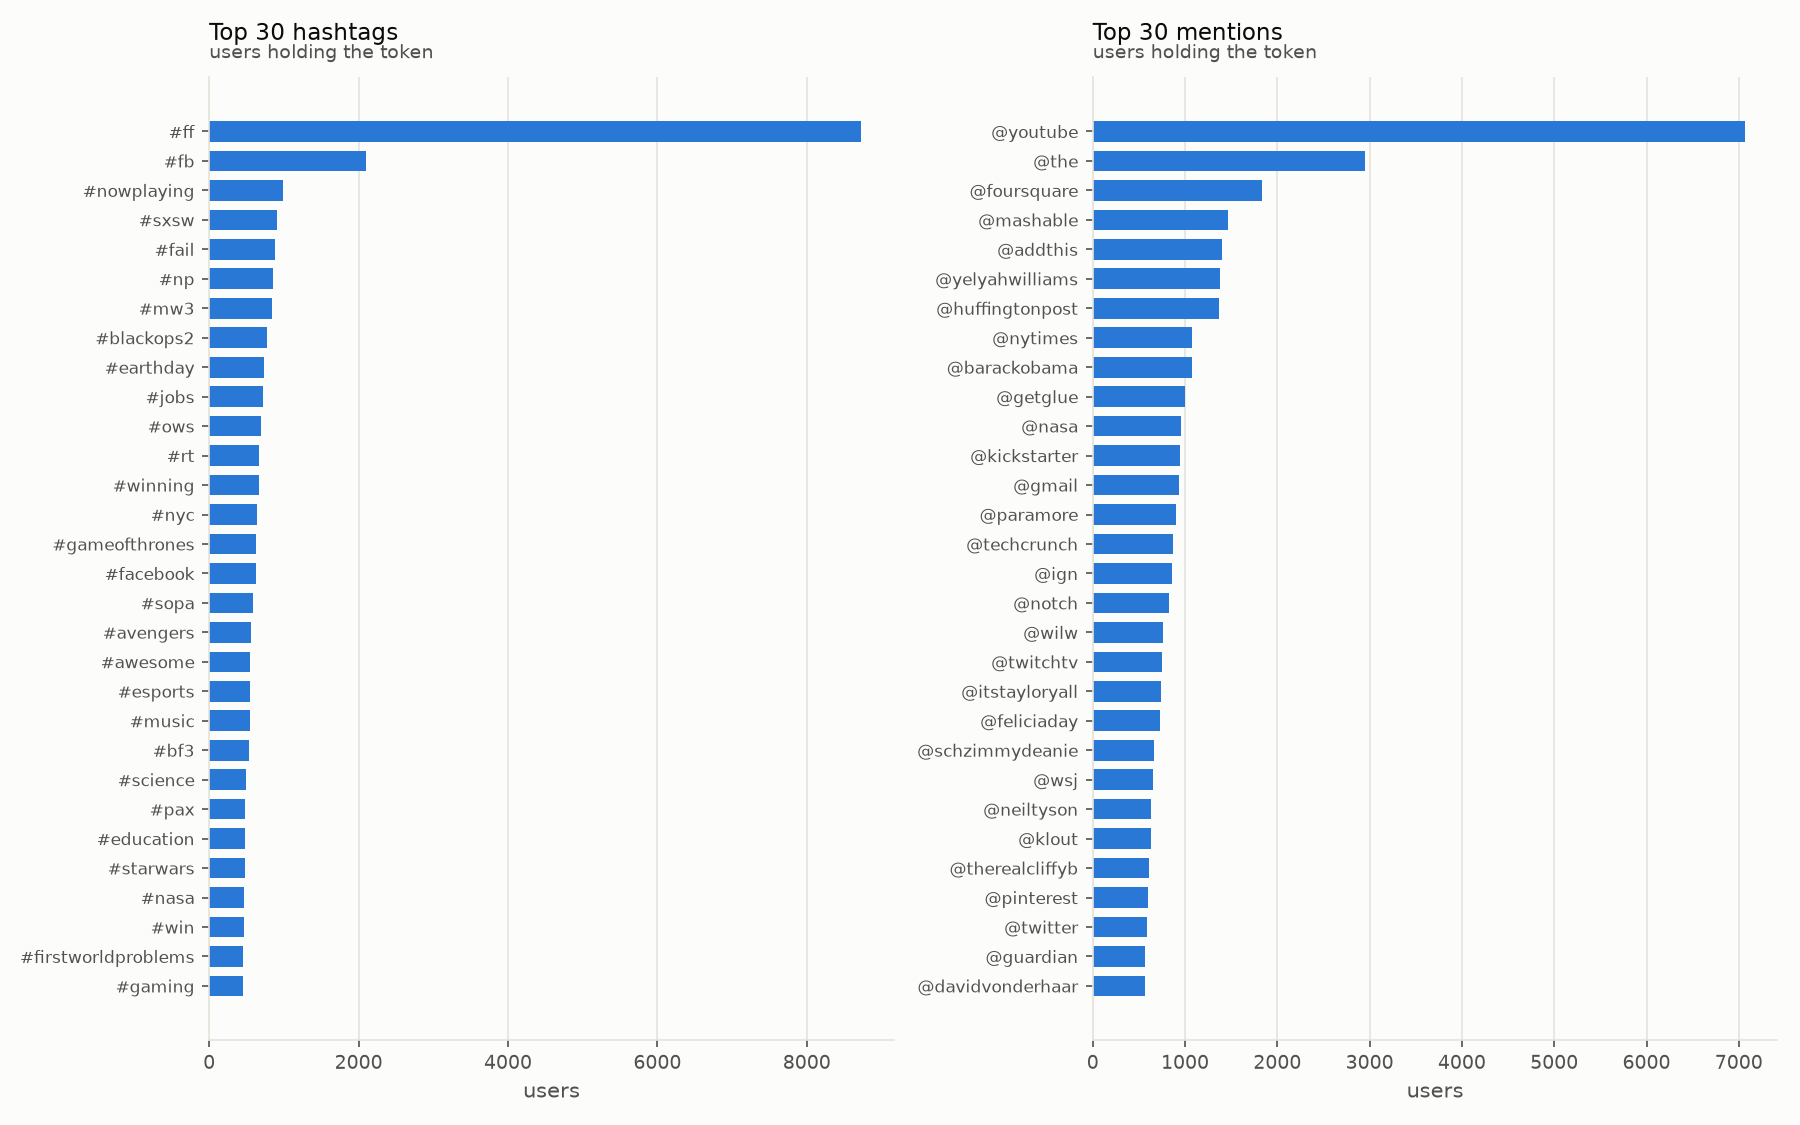

In [8]:
show(eda.plot_top_tokens, "eda_top_tokens.png")

**Reading:** the most common tokens are generic Twitter habits rather than interests —
`#ff` (Follow Friday), `#fb`, `#rt`, `#nowplaying`, `@youtube`, `@the`. TF-IDF gives these low weight
because so many users share them. Below them are real topical clusters: gaming (`#mw3`, `#blackops2`, `#bf3`,
`#esports`, `@ign`, `@twitchtv`), tech news (`@mashable`, `@techcrunch`), news (`@nytimes`, `@huffingtonpost`),
science (`#science`, `#nasa`, `@neiltyson`) and politics (`#ows`, `#sopa`, `@barackobama`).

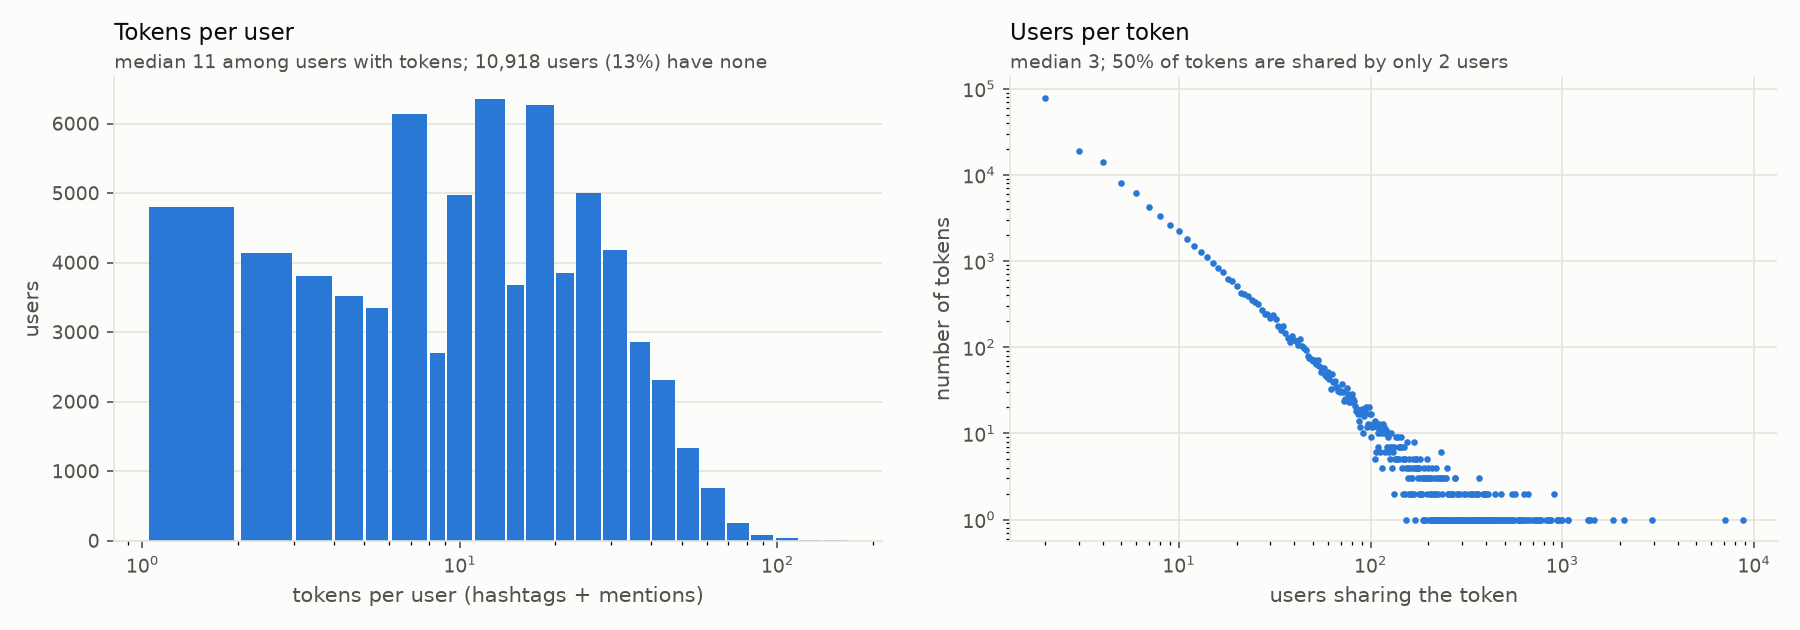

In [9]:
show(eda.plot_interest_sparsity, "eda_interest_sparsity.png")

**Reading:** interest data is **sparse**. 13% of users have no tokens at all, and the typical token is shared
by only a few users. Two consequences for community detection:

- users without tokens can only be placed through follow edges — the reason the **hybrid** mode exists;
- in the **interest** graph many users find no neighbour above `--min-sim`, so only about 61% end up in a community.

## 6. Ground-truth circles

In [10]:
pd.Series({
    "ego networks with circles": stats["egos_with_circles"],
    "circles": f"{stats['n_circles']:,}",
    "median circle size": stats["circle_size_median"],
    "largest circle": stats["circle_size_max"],
    "single-member circles": stats["single_member_circles"],
    "users in >1 circle (mean per ego)": f"{stats['overlap_rate']:.1%}",
    "ego users covered by any circle (mean)": f"{stats['circle_coverage']:.1%}",
}).to_frame("value")

,value
ego networks with circles,938
circles,"4,065"
median circle size,7.0
largest circle,207
single-member circles,520
users in >1 circle (mean per ego),18.1%
ego users covered by any circle (mean),27.5%


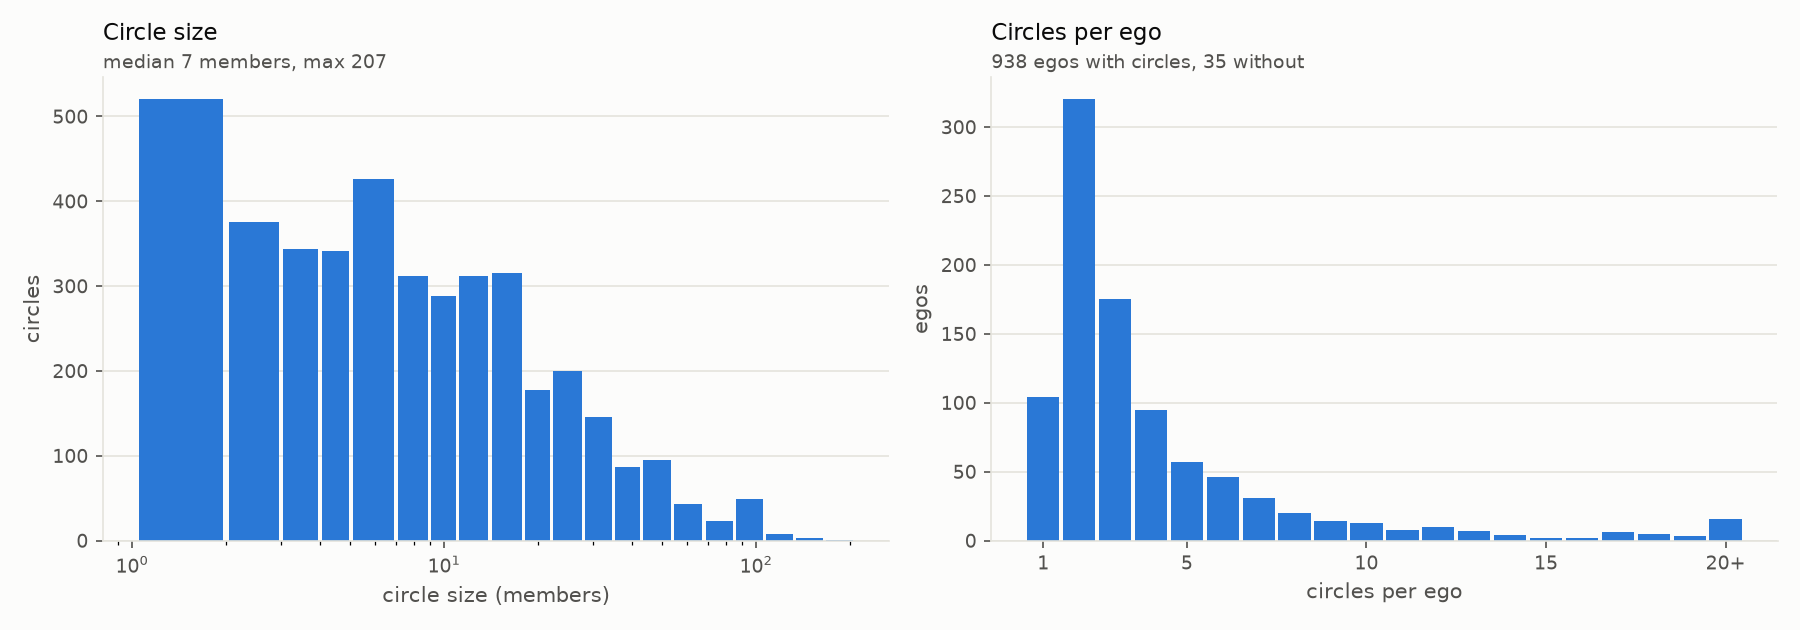

In [11]:
show(eda.plot_circles, "eda_circles.png")

**Reading:** circles are user-made lists, not complete community labels:

- they cover only about **27%** of each ego network, so circle F1 is scored only on users who are in a circle;
- about **18%** of circle members sit in more than one circle, but LPA gives each user exactly one community,
  so a perfect F1 of 1.0 is impossible;
- most egos have only 1–3 circles, and 520 circles have a single member.

Because of this, circle F1 must be read next to the *one-community baseline* added in step 5.

## 7. What this means for the experiments

| Finding | Effect on community detection | What we do |
|---|---|---|
| Ego networks are dense (median 11%) | LPA collapses into one giant community on follow edges | report `largest_share`; prefer `--direction mutual` |
| 48% of follows are mutual | mutual edges keep the stronger half of the ties | `--direction mutual` |
| 13% of users have no tokens; tokens are sparse | interest graph leaves many users alone | hybrid mode adds follow edges |
| Generic tokens dominate (`#ff`, `@youtube`) | they would link unrelated users | TF-IDF down-weights them |
| Trailing punctuation split tokens | the same interest counted as two | `normalize_token` cuts to word characters |
| Circles cover 27% of users and overlap | F1 ceiling < 1 and favours big communities | score only circle members; compare with the one-community baseline |

In [12]:
# Save every number above for the report
Path("outputs/eda_stats.json").write_text(json.dumps(stats, indent=2))
print("saved outputs/eda_stats.json and", len(eda.FIGURES), "figures in", FIG)

saved outputs/eda_stats.json and 5 figures in outputs/figures
